# Final model · partial positions (0% / 50% / 100%)

Plan: [docs/v4_partial_positions_note.md](../docs/v4_partial_positions_note.md), written before this notebook. This is a strategy change only: the model, its settings and its probabilities are the frozen final model's (v4).

Each week, using P(large loss):
- **100%** in SPY below `a`;
- **50%** from `a` to below `b`;
- **0%** at `b` or above.

Fills are at the next open, costs apply to the amount traded, and cash earns T-bills. The selection target is the same as v4's: at least 85% of buy-and-hold's return and an average position of at least 70%, then the smallest max drawdown.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, v2, v3, weekly
from src.data import load_snapshot
from src.dataset import build_dataset

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.OUTPUT_DIR / "v4"; FIG = OUT / "figures"
F = json.loads((OUT / "frozen_config.json").read_text())
M, P = F["model"], F["params"]
print("frozen final model:", M, P)
raw = load_snapshot(); px = raw[["Open", "Close"]]; rf = v2.load_tbill_daily(raw.index)
ds = build_dataset(raw, label_kind="open", buy_thr=0.01, sell_thr=-0.02)
BANDS = [(0.15, 0.30), (0.20, 0.30), (0.20, 0.40), (0.25, 0.40), (0.30, 0.40)]
ALL_IN = [0.20, 0.30, 0.40]

def run(held_w, prices, rfs):
    sim = v2.simulate_weights(held_w, prices.loc[held_w.index], rfs.loc[held_w.index])
    return sim, v2.summarize_weights(sim, held_w, rfs.loc[held_w.index], "")
def held_partial(p, a, b):
    return weekly.weekly_weights_from_risk(p, a, b).shift(1).fillna(1.0)
def held_all_in(p, tau):
    return weekly.weekly_weights_from_risk(p, tau, tau).shift(1).fillna(1.0)

frozen final model: HGB {'clf__l2_regularization': 0.17336465350777208, 'clf__learning_rate': 0.032268708256236636, 'clf__max_depth': 3, 'clf__max_iter': 51, 'clf__min_samples_leaf': 153}


## 1 · Development 2013–2022 (selection)

In [2]:
p_dev = v3.walk_forward_proba(ds, "C2", list(range(2013, 2023)), P, M)[-1]
_, bh = run(pd.Series(1.0, index=p_dev.index), px, rf)
rows = []
for a, b in BANDS:
    _, s = run(held_partial(p_dev, a, b), px, rf)
    rows.append({"strategy": f"partial {a:.2f}/{b:.2f}", "kind": "partial", "a": a, "b": b, **{k: s[k] for k in ["final_value", "cagr", "max_drawdown", "sharpe_excess", "exposure", "position_changes"]}})
for t in ALL_IN:
    _, s = run(held_all_in(p_dev, t), px, rf)
    rows.append({"strategy": f"all-in/out {t:.2f}", "kind": "all-in/out", "a": t, "b": t, **{k: s[k] for k in ["final_value", "cagr", "max_drawdown", "sharpe_excess", "exposure", "position_changes"]}})
dev = pd.DataFrame(rows)
dev["share_of_bh_return"] = dev["cagr"] / bh["cagr"]
print("Buy & Hold 2013–22:", {k: bh[k] for k in ["final_value", "cagr", "max_drawdown", "sharpe_excess"]})
display(dev.sort_values("max_drawdown", ascending=False))

cand = dev[dev["kind"] == "partial"]
elig = cand[(cand["share_of_bh_return"] >= 0.85) & (cand["exposure"] >= 0.70)]
if len(elig):
    pick = elig.sort_values(["max_drawdown", "sharpe_excess"], ascending=[False, False]).iloc[0]; how = "target met"
else:
    pool = cand[cand["exposure"] >= 0.70].assign(calmar=lambda d: d["cagr"] / d["max_drawdown"].abs())
    pick = pool.sort_values("calmar", ascending=False).iloc[0]; how = "fallback: highest Calmar"
FROZEN = {"strategy": "partial positions", "a": float(pick["a"]), "b": float(pick["b"]), "model": M, "selection": how,
          "dev_cagr": float(pick["cagr"]), "dev_max_drawdown": float(pick["max_drawdown"]), "dev_sharpe": float(pick["sharpe_excess"]),
          "dev_bh": {k: bh[k] for k in ["cagr", "max_drawdown", "sharpe_excess"]}, "frozen_before_reporting": True}
(OUT / "partial_frozen_config.json").write_text(json.dumps(FROZEN, indent=2))
FROZEN

Buy & Hold 2013–22: {'final_value': 316843.58, 'cagr': 0.1223, 'max_drawdown': -0.3372, 'sharpe_excess': 0.708}


,strategy,kind,a,b,final_value,cagr,max_drawdown,sharpe_excess,exposure,position_changes,share_of_bh_return
0,partial 0.15/0.30,partial,0.1500,0.3000,"168,488.5200",0.0536,-0.2132,0.4370,0.8340,105,0.4383
5,all-in/out 0.20,all-in/out,0.2000,0.2000,"204,488.1000",0.0742,-0.2221,0.5430,0.8660,61,0.6067
1,partial 0.20/0.30,partial,0.2000,0.3000,"230,032.4200",0.0869,-0.2415,0.6060,0.9230,71,0.7105
2,partial 0.20/0.40,partial,0.2000,0.4000,"252,989.2200",0.0973,-0.2623,0.6630,0.9320,63,0.7956
6,all-in/out 0.30,all-in/out,0.3000,0.3000,"255,239.6900",0.0983,-0.2951,0.6130,0.9810,10,0.8038
3,partial 0.25/0.40,partial,0.2500,0.4000,"261,545.5600",0.1010,-0.3127,0.6310,0.9760,20,0.8258
4,partial 0.30/0.40,partial,0.3000,0.4000,"281,999.7000",0.1093,-0.3127,0.6660,0.9890,12,0.8937
7,all-in/out 0.40,all-in/out,0.4000,0.4000,"309,788.8200",0.1198,-0.3372,0.6970,0.9980,2,0.9796


{'strategy': 'partial positions',
 'a': 0.3,
 'b': 0.4,
 'model': 'HGB',
 'selection': 'target met',
 'dev_cagr': 0.1093,
 'dev_max_drawdown': -0.3127,
 'dev_sharpe': 0.666,
 'dev_bh': {'cagr': 0.1223, 'max_drawdown': -0.3372, 'sharpe_excess': 0.708},
 'frozen_before_reporting': True}

## 2 · Reported periods

2023–24 test


,final_value,cagr,ann_vol,max_drawdown,sharpe_excess,exposure,position_changes,total_fees
strategy,,,,,,,,
partial,"156,546.2500",0.2523,0.1283,-0.0997,1.4300,1.0000,0,99.9000
final (all-in/out),"156,546.2500",0.2523,0.1283,-0.0997,1.4300,1.0000,0,99.9000
Buy & Hold,"156,546.2500",0.2523,0.1283,-0.0997,1.4300,1.0000,0,99.9000


2013–24 walk-forward


,final_value,cagr,ann_vol,max_drawdown,sharpe_excess,exposure,position_changes,total_fees
strategy,,,,,,,,
partial,"444,365.1800",0.1325,0.1595,-0.3127,0.7690,0.9910,12,"1,339.6100"
final (all-in/out),"488,154.2800",0.1414,0.1664,-0.3372,0.7910,0.9980,2,539.5900
Buy & Hold,"499,270.9200",0.1436,0.1670,-0.3372,0.8000,1.0000,0,99.9000


2025–26 holdout


,final_value,cagr,ann_vol,max_drawdown,sharpe_excess,exposure,position_changes,total_fees
strategy,,,,,,,,
partial,"139,986.2200",0.2098,0.1683,-0.1876,0.9860,0.9910,2,284.5800
final (all-in/out),"139,986.2200",0.2098,0.1683,-0.1876,0.9860,0.9910,2,284.5800
Buy & Hold,"134,409.7400",0.1823,0.1694,-0.1876,0.8440,1.0000,0,99.9000


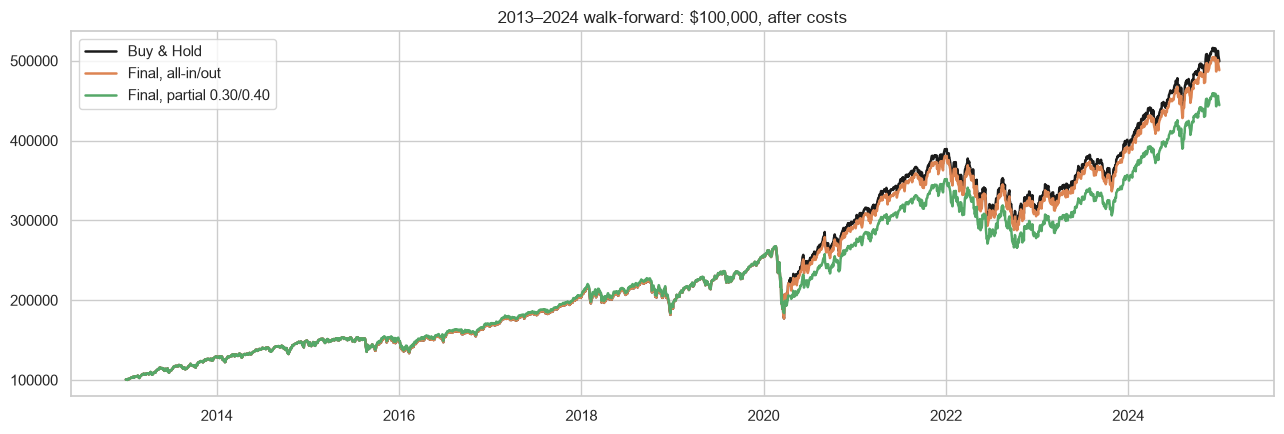

saved outputs/v4/partial_*


In [3]:
A, B = FROZEN["a"], FROZEN["b"]
HOLD = config.ROOT / "data" / "holdout"
raw_h = pd.read_csv(HOLD / "spy_20261013.csv", index_col=0, parse_dates=True)
rf_h = v2.load_tbill_daily(raw_h.index, HOLD / "irx_20261013.csv")
ds_h = build_dataset(raw_h, label_kind="open", buy_thr=0.01, sell_thr=-0.02)
RES, PATHS = {}, {}
for label, data, prices, rfs, years in [("2023–24 test", ds, px, rf, [2023, 2024]),
                                         ("2013–24 walk-forward", ds, px, rf, list(range(2013, 2025))),
                                         ("2025–26 holdout", ds_h, raw_h[["Open", "Close"]], rf_h, [2025, 2026])]:
    p = v3.walk_forward_proba(data, "C2", years, P, M)[-1]
    sp, s = run(held_partial(p, A, B), prices, rfs)
    sa, a_ = run(held_all_in(p, F["tau"]), prices, rfs)
    sb, b_ = run(pd.Series(1.0, index=p.index), prices, rfs)
    RES[label] = {"partial": s, "final_all_in": a_, "buy_and_hold": b_}
    PATHS[label] = {"dates": [d.strftime("%Y-%m-%d") for d in p.index], "partial": [round(float(x)) for x in sp["value"]],
                    "final_all_in": [round(float(x)) for x in sa["value"]], "bh": [round(float(x)) for x in sb["value"]]}
    show = pd.DataFrame([dict(s, strategy="partial"), dict(a_, strategy="final (all-in/out)"), dict(b_, strategy="Buy & Hold")]).set_index("strategy")
    print(label); display(show[["final_value", "cagr", "ann_vol", "max_drawdown", "sharpe_excess", "exposure", "position_changes", "total_fees"]])

fig, ax = plt.subplots(figsize=(13, 4.5))
k = "2013–24 walk-forward"; d = pd.to_datetime(PATHS[k]["dates"])
for key, col, lab in [("bh", "k", "Buy & Hold"), ("final_all_in", "C1", "Final, all-in/out"), ("partial", "C2", f"Final, partial {A:.2f}/{B:.2f}")]:
    ax.plot(d, PATHS[k][key], color=col, lw=1.8, label=lab)
ax.set_title("2013–2024 walk-forward: $100,000, after costs"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "partial_positions_paths.png", dpi=120, bbox_inches="tight"); plt.show()
(OUT / "partial_results.json").write_text(json.dumps({"frozen": FROZEN, "development": dev.to_dict(orient="records"), "development_bh": bh, "results": RES}, indent=2, default=str))
(OUT / "partial_paths.json").write_text(json.dumps(PATHS))
print("saved outputs/v4/partial_*")